In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# support for running notebook from either project root or notebooks/
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "processed" / "netflix_cleaned_dataset.csv"

df = pd.read_csv(data_path)
print("Shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

Shape: (8790, 10)
Columns: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
content_counts = df["type"].value_counts().reindex(
    ["Movie", "TV Show"], fill_value=0
)

content_percentages = content_counts / len(df) * 100

content_summary = pd.DataFrame({
    "Count": content_counts,
    "Percentage": content_percentages.round(2)
})
display(content_summary)

,Count,Percentage
type,,
Movie,6126,69.69
TV Show,2664,30.31


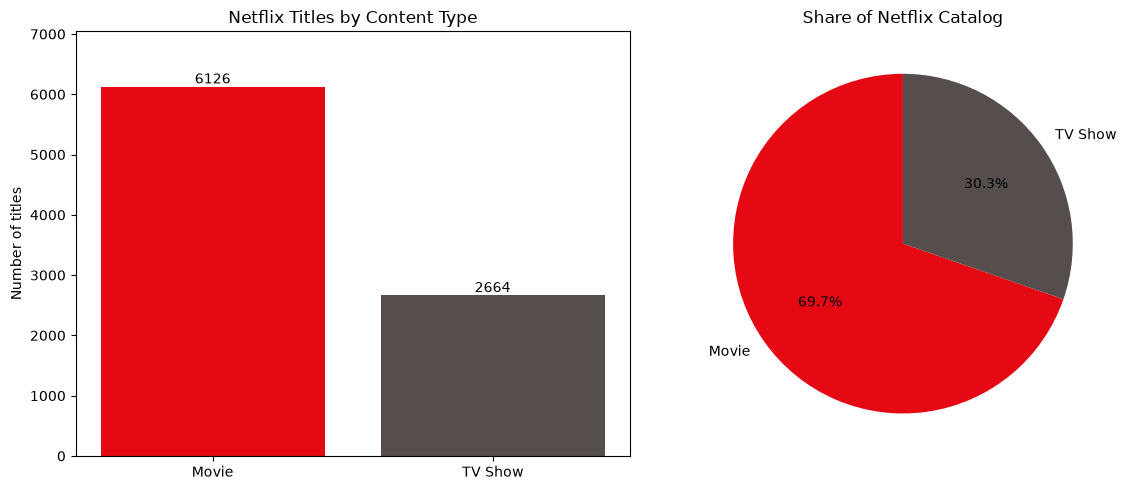

In [6]:
# visualization
labels = content_counts.index
counts = content_counts.values
percentages = content_percentages.values
colors = ["#E50914", "#564D4D"]  

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# the counts
bars = axes[0].bar(labels, counts, color=colors)
axes[0].set_title("Netflix Titles by Content Type")
axes[0].set_ylabel("Number of titles")
axes[0].bar_label(bars, fmt="%.0f")
axes[0].set_ylim(0, max(counts) * 1.15)

axes[1].pie(
    counts,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors
)
axes[1].set_title("Share of Netflix Catalog")

fig.tight_layout()
plt.show()

# Key findings

- **Content mix:** The cleaned dataset contains 8,790 titles: 6,126 Movies (69.69%) and 2,664 TV Shows (30.31%).
- **Comparison:** Movies outnumber TV Shows by 3,462 titles, or about 2.3 times as many.

These figures describe the dataset analyzed; they should not be interpreted as a live count of Netflix's current catalog.